In [ ]:
import pandas as pd

print("Hello! Welcome to my Data Science Internship Project!")

Hello! Welcome to my Data Science Internship Project!


In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
# Check the size of the dataset
print("Dataset shape:")
print(df.shape)

# Display information about the dataset
print("\nDataset information:")
df.info()

# Display basic statistics
print("\nBasic statistics:")
df.describe()

Dataset shape:
(891, 12)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Basic statistics:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
# Check missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [ ]:
# Fill missing Age values with the median age
df["Age"] = df["Age"].fillna(df["Age"].median())

# Remove the Cabin column because it has too many missing values
df = df.drop("Cabin", axis=1)

# Fill missing Embarked values with the most common value
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Check missing values again
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [ ]:
# Check for duplicate rows
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [ ]:
# Check for possible outliers using basic statistics

print("Age statistics:")
print(df["Age"].describe())

print("\nFare statistics:")
print(df["Fare"].describe())

Age statistics:
count    891.000000
mean      29.361582
std       13.019697
min        0.420000
25%       22.000000
50%       28.000000
75%       35.000000
max       80.000000
Name: Age, dtype: float64

Fare statistics:
count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64


In [ ]:
# Calculate the IQR for Fare
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)

IQR = Q3 - Q1

# Calculate the lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

# Count possible outliers
outliers = df[(df["Fare"] < lower_limit) | (df["Fare"] > upper_limit)]

print("Number of possible Fare outliers:", len(outliers))

Q1: 7.9104
Q3: 31.0
IQR: 23.0896
Lower limit: -26.724
Upper limit: 65.6344
Number of possible Fare outliers: 116


In [ ]:
# Check the data types of all columns
print("Data types:")
print(df.dtypes)

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Embarked        object
dtype: object


In [ ]:
# Remove columns that are not needed for our analysis
df = df.drop(["Name", "Ticket"], axis=1)

# Convert Sex into numbers
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

# Convert Embarked into separate numerical columns
df = pd.get_dummies(df, columns=["Embarked"], dtype=int)

# Display the first 5 rows
print(df.head())

   PassengerId  Survived  Pclass  Sex   Age  SibSp  Parch     Fare  \
0            1         0       3    0  22.0      1      0   7.2500   
1            2         1       1    1  38.0      1      0  71.2833   
2            3         1       3    1  26.0      0      0   7.9250   
3            4         1       1    1  35.0      1      0  53.1000   
4            5         0       3    0  35.0      0      0   8.0500   

   Embarked_C  Embarked_Q  Embarked_S  
0           0           0           1  
1           1           0           0  
2           0           0           1  
3           0           0           1  
4           0           0           1  


In [ ]:
# Final check of the cleaned dataset

print("Final dataset shape:")
print(df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nFinal data types:")
print(df.dtypes)

Final dataset shape:
(891, 11)

Missing values:
PassengerId    0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked_C     0
Embarked_Q     0
Embarked_S     0
dtype: int64

Duplicate rows:
0

Final data types:
PassengerId      int64
Survived         int64
Pclass           int64
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Fare           float64
Embarked_C       int64
Embarked_Q       int64
Embarked_S       int64
dtype: object


In [ ]:
# Save the cleaned dataset as a CSV file

df.to_csv("titanic_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


WEEK 2 – EXPLORATORY DATA ANALYSIS AND VISUALIZATION


## 1. Introduction and Objective


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned Titanic dataset
df = pd.read_csv("titanic_cleaned.csv")

# Display the first 5 rows
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,0,22.0,1,0,7.2500,0,0,1
1,2,1,1,1,38.0,1,0,71.2833,1,0,0
2,3,1,3,1,26.0,0,0,7.9250,0,0,1
3,4,1,1,1,35.0,1,0,53.1000,0,0,1
4,5,0,3,0,35.0,0,0,8.0500,0,0,1


In [3]:
# Step 2 - Initial EDA

print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nBasic statistical summary:")
print(df.describe())

Dataset shape:
(891, 11)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

Basic statistical summary:
       PassengerId    Survived      Pclass         Sex         Age  \
count   891.000000  891.000000  891.000000  891.000000  891.000000   
mean    446.000000    0.383838    2.308642    0.352413   29.361582   
std     257.353842    0.486592    0.836071    0.477990   13.019697   
min       1.000000    0.000000    1.000000    0.000000    0.420000   
25%     223.500000    0.000000    2.000000    0.000000   22.000000   
50%     446.000000    0.000000    3.000000    0.000000   28.000000   
75%     668.500000    1.000000    3.000000    1.000000   35.000000   
max     891.000000    1.000000    3.000000    1.000000   80.000000   

            SibSp       Parch        Fare  Embarked_C  Embarked_Q  Embarked_S  
count  891.000000  891.000000  891.000000  891.000000  891.000000  891.000000  
mean     0.523008    

In [4]:
# Step 3 - Analyze survival

survival_counts = df["Survived"].value_counts()

print("Survival counts:")
print(survival_counts)

print("\nSurvival percentages:")
print(df["Survived"].value_counts(normalize=True) * 100)

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


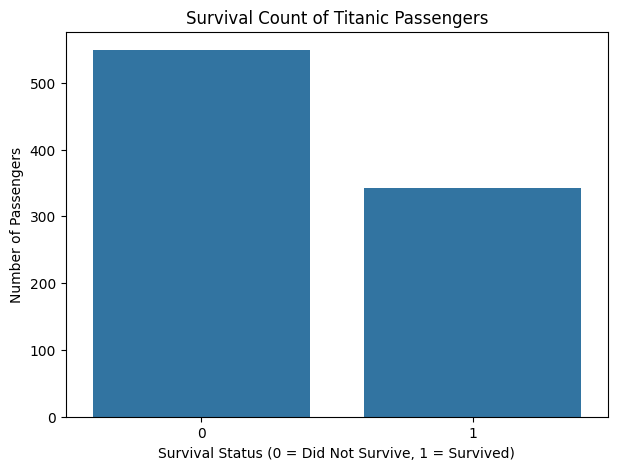

In [5]:
# Step 4 - Visualize survival counts

plt.figure(figsize=(7, 5))

sns.countplot(x="Survived", data=df)

plt.title("Survival Count of Titanic Passengers")
plt.xlabel("Survival Status (0 = Did Not Survive, 1 = Survived)")
plt.ylabel("Number of Passengers")

plt.show()

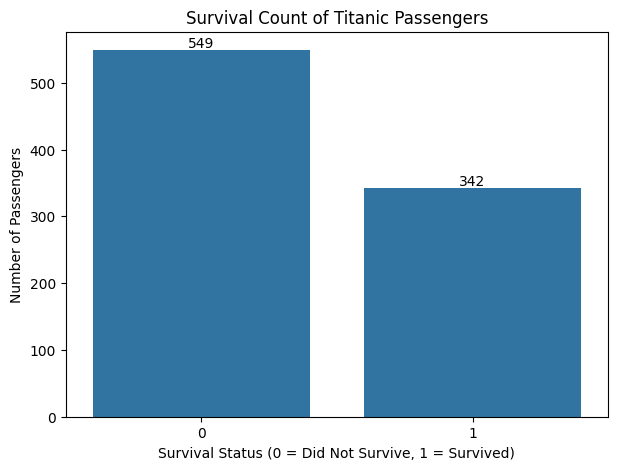

In [6]:
# Step 4A - Add values to the survival chart

plt.figure(figsize=(7, 5))

ax = sns.countplot(x="Survived", data=df)

plt.title("Survival Count of Titanic Passengers")
plt.xlabel("Survival Status (0 = Did Not Survive, 1 = Survived)")
plt.ylabel("Number of Passengers")

# Add the count above each bar
for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [7]:
# Step 5 - Analyze passengers by gender

gender_counts = df["Sex"].value_counts()

print("Passenger count by gender:")
print(gender_counts)

print("\nGender percentages:")
print(df["Sex"].value_counts(normalize=True) * 100)

Passenger count by gender:
Sex
0    577
1    314
Name: count, dtype: int64

Gender percentages:
Sex
0    64.758698
1    35.241302
Name: proportion, dtype: float64


In [8]:
# Step 6 - Calculate survival rate by gender

gender_survival = df.groupby("Sex")["Survived"].mean() * 100

print("Survival rate by gender:")
print(gender_survival)

Survival rate by gender:
Sex
0    18.890815
1    74.203822
Name: Survived, dtype: float64


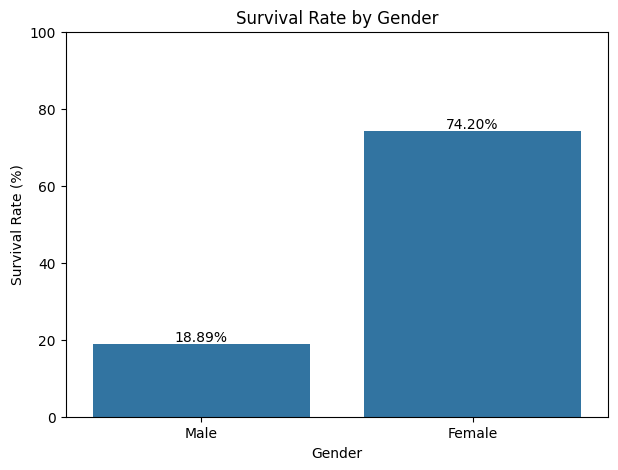

In [9]:
# Step 7 - Visualize survival rate by gender

gender_survival_df = gender_survival.reset_index()
gender_survival_df.columns = ["Sex", "SurvivalRate"]

# Convert codes to readable labels
gender_survival_df["Gender"] = gender_survival_df["Sex"].map({
    0: "Male",
    1: "Female"
})

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x="Gender",
    y="SurvivalRate",
    data=gender_survival_df
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")

# Add percentages on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.ylim(0, 100)
plt.show()

In [10]:
# Step 8 - Analyze passenger class

class_counts = df["Pclass"].value_counts().sort_index()

print("Passenger count by class:")
print(class_counts)

print("\nPassenger class percentages:")
print(df["Pclass"].value_counts(normalize=True).sort_index() * 100)

Passenger count by class:
Pclass
1    216
2    184
3    491
Name: count, dtype: int64

Passenger class percentages:
Pclass
1    24.242424
2    20.650954
3    55.106622
Name: proportion, dtype: float64


In [11]:
# Step 9 - Calculate survival rate by passenger class

class_survival = df.groupby("Pclass")["Survived"].mean() * 100

print("Survival rate by passenger class:")
print(class_survival)

Survival rate by passenger class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


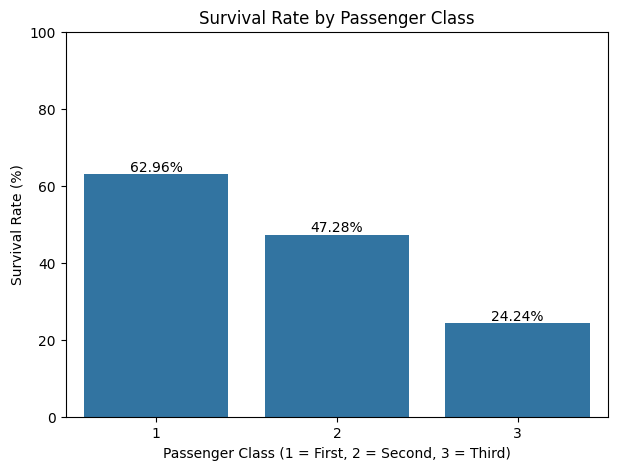

In [12]:
# Step 10 - Visualize survival rate by passenger class

class_survival_df = class_survival.reset_index()
class_survival_df.columns = ["Pclass", "SurvivalRate"]

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x="Pclass",
    y="SurvivalRate",
    data=class_survival_df
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Survival Rate (%)")

# Add percentages above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.ylim(0, 100)
plt.show()

In [13]:
# Step 11 - Analyze passenger age

print("Age statistics:")

print("Mean age:", df["Age"].mean())
print("Median age:", df["Age"].median())
print("Minimum age:", df["Age"].min())
print("Maximum age:", df["Age"].max())

Age statistics:
Mean age: 29.36158249158249
Median age: 28.0
Minimum age: 0.42
Maximum age: 80.0


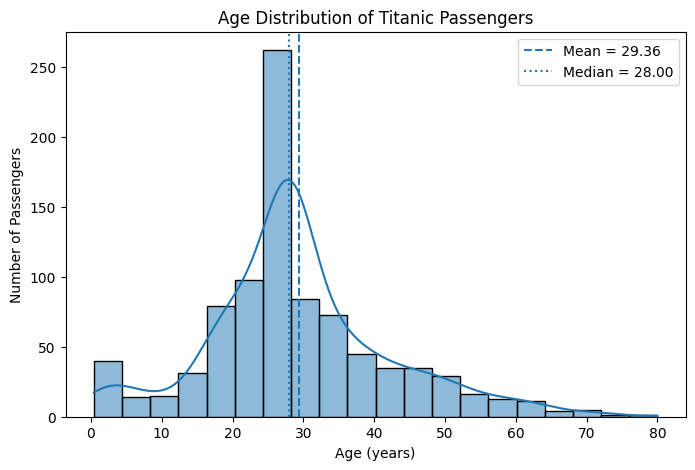

In [14]:
# Step 12 - Visualize the age distribution

plt.figure(figsize=(8, 5))

sns.histplot(df["Age"], bins=20, kde=True)

# Add mean and median lines
plt.axvline(
    df["Age"].mean(),
    linestyle="--",
    label=f"Mean = {df['Age'].mean():.2f}"
)

plt.axvline(
    df["Age"].median(),
    linestyle=":",
    label=f"Median = {df['Age'].median():.2f}"
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age (years)")
plt.ylabel("Number of Passengers")
plt.legend()

plt.show()

In [15]:
# Step 13 - Analyze Fare distribution

print("Fare statistics:")

print("Mean fare:", df["Fare"].mean())
print("Median fare:", df["Fare"].median())
print("Minimum fare:", df["Fare"].min())
print("Maximum fare:", df["Fare"].max())

Fare statistics:
Mean fare: 32.204207968574636
Median fare: 14.4542
Minimum fare: 0.0
Maximum fare: 512.3292


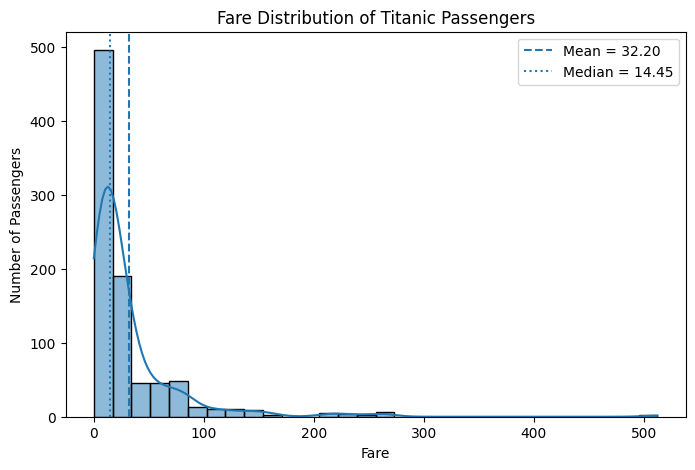

In [16]:
# Step 14 - Visualize Fare distribution

plt.figure(figsize=(8, 5))

sns.histplot(df["Fare"], bins=30, kde=True)

# Add mean and median lines
plt.axvline(
    df["Fare"].mean(),
    linestyle="--",
    label=f"Mean = {df['Fare'].mean():.2f}"
)

plt.axvline(
    df["Fare"].median(),
    linestyle=":",
    label=f"Median = {df['Fare'].median():.2f}"
)

plt.title("Fare Distribution of Titanic Passengers")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")
plt.legend()

plt.show()

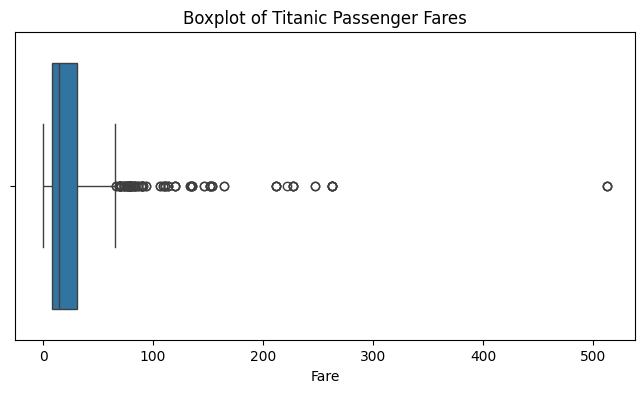

In [17]:
# Step 15 - Visualize Fare outliers with a boxplot

plt.figure(figsize=(8, 4))

sns.boxplot(x=df["Fare"])

plt.title("Boxplot of Titanic Passenger Fares")
plt.xlabel("Fare")

plt.show()

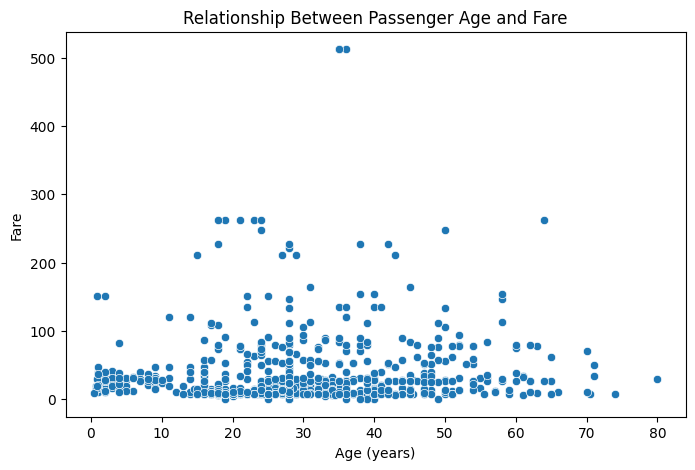

In [18]:
# Step 16 - Age vs Fare

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="Age",
    y="Fare",
    data=df
)

plt.title("Relationship Between Passenger Age and Fare")
plt.xlabel("Age (years)")
plt.ylabel("Fare")

plt.show()

In [19]:
# Step 17 - Calculate correlation between Age and Fare

correlation = df["Age"].corr(df["Fare"])

print("Correlation between Age and Fare:", correlation)

Correlation between Age and Fare: 0.09668842218036484


In [20]:
# Step 18 - Create Family Size

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

print("Family Size statistics:")
print(df["FamilySize"].describe())

Family Size statistics:
count    891.000000
mean       1.904602
std        1.613459
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       11.000000
Name: FamilySize, dtype: float64


In [21]:
# Step 19 - Survival rate by family size

family_survival = df.groupby("FamilySize")["Survived"].mean() * 100

print("Survival rate by family size:")
print(family_survival)

Survival rate by family size:
FamilySize
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64


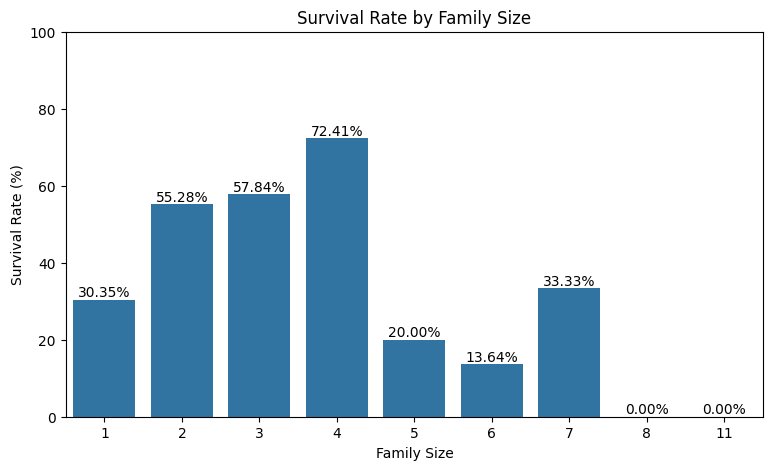

In [22]:
# Step 20 - Visualize survival rate by family size

family_survival_df = family_survival.reset_index()
family_survival_df.columns = ["FamilySize", "SurvivalRate"]

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x="FamilySize",
    y="SurvivalRate",
    data=family_survival_df
)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate (%)")

# Add percentage values
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.ylim(0, 100)
plt.show()

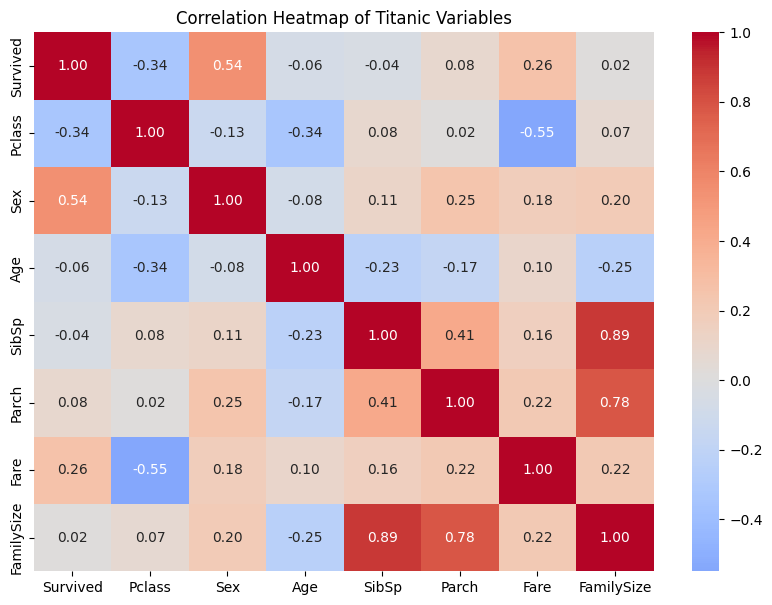

In [23]:
# Step 21 - Correlation heatmap

correlation_matrix = df[
    ["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "FamilySize"]
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Titanic Variables")
plt.show()

In [24]:
# Step 22 - Survival rate by gender and passenger class

gender_class_survival = (
    df.groupby(["Pclass", "Sex"])["Survived"]
    .mean()
    .reset_index()
)

gender_class_survival["SurvivalRate"] = (
    gender_class_survival["Survived"] * 100
)

# Convert Sex codes to readable names
gender_class_survival["Gender"] = gender_class_survival["Sex"].map({
    0: "Male",
    1: "Female"
})

print("Survival rate by passenger class and gender:")
print(
    gender_class_survival[
        ["Pclass", "Gender", "SurvivalRate"]
    ]
)

Survival rate by passenger class and gender:
   Pclass  Gender  SurvivalRate
0       1    Male     36.885246
1       1  Female     96.808511
2       2    Male     15.740741
3       2  Female     92.105263
4       3    Male     13.544669
5       3  Female     50.000000


In [25]:
# Step 23 - Count passengers in each gender/class group

group_counts = df.groupby(["Pclass", "Sex"]).size().reset_index(name="PassengerCount")

group_counts["Gender"] = group_counts["Sex"].map({
    0: "Male",
    1: "Female"
})

print("Passenger count by class and gender:")
print(group_counts[["Pclass", "Gender", "PassengerCount"]])

Passenger count by class and gender:
   Pclass  Gender  PassengerCount
0       1    Male             122
1       1  Female              94
2       2    Male             108
3       2  Female              76
4       3    Male             347
5       3  Female             144


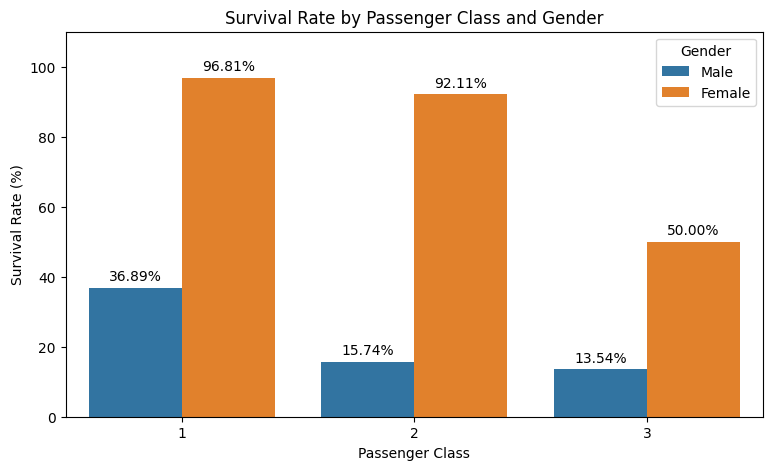

In [26]:
# Step 24 - Visualize survival by gender and passenger class

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x="Pclass",
    y="SurvivalRate",
    hue="Gender",
    data=gender_class_survival
)

plt.title("Survival Rate by Passenger Class and Gender")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.legend(title="Gender")

# Add percentage values
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.ylim(0, 110)
plt.show()

In [27]:
# Step 25 - Summary of important EDA findings

print("KEY EDA FINDINGS")
print("-" * 40)

print(f"Total passengers: {len(df)}")

print(f"Overall survival rate: {df['Survived'].mean() * 100:.2f}%")

print(f"Female survival rate: {gender_survival[1]:.2f}%")
print(f"Male survival rate: {gender_survival[0]:.2f}%")

print(f"1st class survival rate: {class_survival[1]:.2f}%")
print(f"2nd class survival rate: {class_survival[2]:.2f}%")
print(f"3rd class survival rate: {class_survival[3]:.2f}%")

print(f"Age mean: {df['Age'].mean():.2f}")
print(f"Age median: {df['Age'].median():.2f}")

print(f"Fare mean: {df['Fare'].mean():.2f}")
print(f"Fare median: {df['Fare'].median():.2f}")

print(f"Age-Fare correlation: {correlation:.4f}")

KEY EDA FINDINGS
----------------------------------------
Total passengers: 891
Overall survival rate: 38.38%
Female survival rate: 74.20%
Male survival rate: 18.89%
1st class survival rate: 62.96%
2nd class survival rate: 47.28%
3rd class survival rate: 24.24%
Age mean: 29.36
Age median: 28.00
Fare mean: 32.20
Fare median: 14.45
Age-Fare correlation: 0.0967


In [28]:
# Step 26 - Create age groups

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 17, 34, 59, 100],
    labels=["Child", "Teenager", "Adult", "Middle-aged", "Senior"],
    include_lowest=True
)

# Calculate passenger count and survival rate by age group
age_group_analysis = df.groupby("AgeGroup", observed=False)["Survived"].agg(
    PassengerCount="count",
    SurvivalRate="mean"
)

age_group_analysis["SurvivalRate"] = age_group_analysis["SurvivalRate"] * 100

print("Age group analysis:")
print(age_group_analysis)

Age group analysis:
             PassengerCount  SurvivalRate
AgeGroup                                 
Child                    69     57.971014
Teenager                 44     47.727273
Adult                   542     34.501845
Middle-aged             210     41.428571
Senior                   26     26.923077


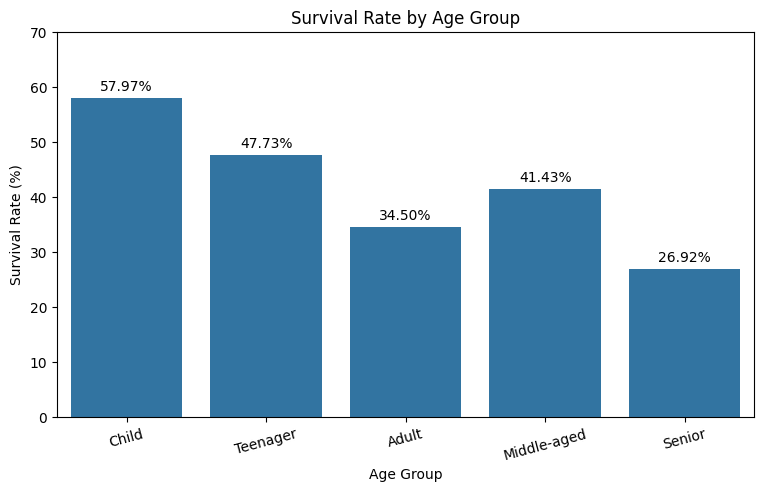

In [29]:
# Step 27 - Visualize survival rate by age group

age_group_plot = age_group_analysis.reset_index()

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x="AgeGroup",
    y="SurvivalRate",
    data=age_group_plot
)

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")

# Add percentages above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.ylim(0, 70)
plt.xticks(rotation=15)

plt.show()

In [30]:
# Step 28 - Final missing-value check

print("Missing values after EDA transformations:")
print(df[["Age", "Fare", "FamilySize", "AgeGroup"]].isnull().sum())

Missing values after EDA transformations:
Age           0
Fare          0
FamilySize    0
AgeGroup      0
dtype: int64


## Key Findings and Conclusion

The exploratory data analysis identified several important patterns in the Titanic dataset. The overall survival rate was 38.38%. Female passengers had a substantially higher survival rate (74.20%) than male passengers (18.89%).

Passenger class was also associated with survival. First-class passengers had a survival rate of 62.96%, compared with 47.28% for second class and 24.24% for third class.

The mean passenger age was 29.36 years, while the median was 28 years. Age-group analysis showed that children had the highest observed survival rate (57.97%), while seniors had the lowest (26.92%). The senior group contained only 26 passengers, so this result should be interpreted cautiously.

The mean fare was 32.20, compared with a median of 14.45, indicating that the fare distribution was positively skewed. The correlation between age and fare was weak (0.0967), suggesting little linear relationship between these two variables.

Overall, the EDA indicates that gender and passenger class showed particularly strong differences in observed survival rates. Age groups also displayed differences, although group sizes should be considered when interpreting these results.